# **COMP 2211 Introduction to Artificial Intelligence** #
# Programming Assignment 2 - I'm Not a Robot #

<img src="https://i.imgur.com/Qpxe4ma.png" alt="captcha" height="400">

In [1]:
# classic imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2 # opencv

# system imports
import os
import zipfile

# keras/sklearn imports
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, UpSampling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# global constant
IMG_SIZE = 64 # don't change

# Introduction and Preparing the Dataset
In this programming assignment, you will build a CNN and an autoencoder (a special form of CNN) to pass the CAPTCHA test using Pokemon images. Follow the instructions in the notebook to complete the 7 tasks. Please use Google Colab for this assignment to ensure library compatibility with ZINC.

## About the Dataset
For this assignment, we will use a Pokemon images dataset from Keras. The original dataset consists of 143 Pokemon, each with 50 to 200 images. Note that the TAs have provided a smaller sample of this dataset to create hidden test cases, which will be used for grading.

You can visualize the dataset by running the following 2 cells. Before doing so, upload the `Pokemon-images.zip` file to Google Colab by navigating to the Files section on the left. Please be aware that files uploaded to Colab are not permanent; once your runtime disconnects, you will need to re-upload the files to continue working.

In [2]:
if __name__ == '__main__':
    zip_file_path = './Pokemon-images.zip'
    image_dir = './images/'

    # Unzip the dataset
    os.makedirs(image_dir, exist_ok=True)
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(image_dir)

    # Read all image files and group them by pokemon name
    files = [f for f in os.listdir(image_dir)]
    pokemon_images = {}
    for f in files:
        pokemon_name = f.split('_', 1)[0]
        if pokemon_name in pokemon_images:
            pokemon_images[pokemon_name].append(f)
        else:
            pokemon_images[pokemon_name] = [f]

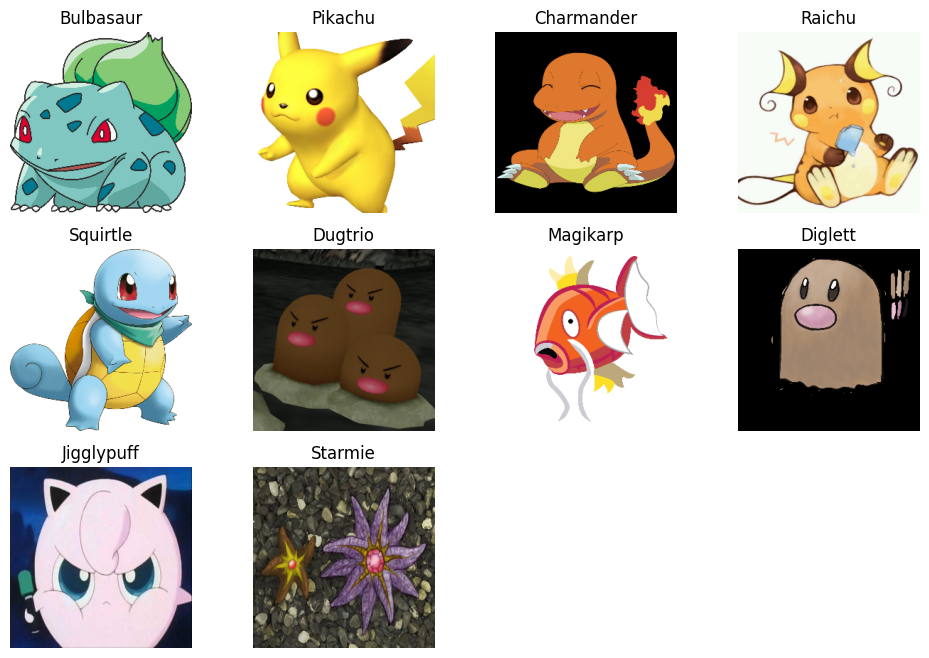

In [3]:
# Plot a sample image for each pokemon in a single figure
if __name__ == '__main__':
    plt.figure(figsize=(12, 8))
    for i, (pokemon, images) in enumerate(pokemon_images.items()):
        img_path = os.path.join(image_dir, images[0])
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(3, 4, i+1)
        plt.imshow(img)
        plt.title(pokemon)
        plt.axis('off')

In [4]:
# Print the number of images for each Pokémon
if __name__ == '__main__':
    for pokemon, images in pokemon_images.items():
        print(f'{pokemon}: {len(images)} images')

Bulbasaur: 100 images
Pikachu: 100 images
Charmander: 100 images
Raichu: 100 images
Squirtle: 100 images
Dugtrio: 100 images
Magikarp: 100 images
Diglett: 40 images
Jigglypuff: 100 images
Starmie: 100 images


In [5]:
# Image translation using opencv
def translate_image(image, tx, ty):
    # TODO (Task 1): Complete the function to translate image (downwards by ty pixels and rightwards by tx pixels)
    # Hint: Use cv2.warpAffine and create the transformation matrix M

    # transformation matrix
    transformation_matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    height, width = image.shape[:2] # it returns three things
    image = cv2.warpAffine(image, transformation_matrix, (width, height))


    return image

# Image rotation using opencv
def rotate_image(image, angle):
    # TODO (Task 2): Complete the function to rotate image for the given angle (in the anticlockwise direction)
    # Hint: Use cv2.getRotationMatrix2D and cv2.warpAffine

    height, width = image.shape[:2]
    center = (width // 2, height // 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0) # (center, angle, scale)
    image = cv2.warpAffine(image, rotation_matrix, (width, height))




    return image

Color Jittering is a data augmentation technique used to generate new images by modifying contrast, brightness, and saturation (note: hue is not included in this assignment).
- Contrast: Changes the degree of difference between the darkest and lightest parts of an image by scaling all pixel values.
- Brightness: Makes the image lighter or darker by applying a linear shift to all pixel values.
- Saturation: Adjusts how far RGB values are from the "gray" center. Because this is complex to perform directly in the RGB color space, we suggest first converting the image to the HSV model and then scaling the S (Saturation) channel.

Write code in the cell below to comeplete task 3. You may find the following documentation useful:
- [cv2.convertScaleAbs](https://docs.opencv.org/4.x/d2/de8/group__core__array.html#ga3460e9c9f37b563ab9dd550c4d8c4e7d)
- [cv2.cvtColor](https://docs.opencv.org/4.x/d8/d01/group__imgproc__color__conversions.html#gaf86c09fe702ed037c03c2bc603ceab14)

**Task 3**: Complete the `color_jitter()` function.

In [6]:
# Color jittering using opencv
def color_jitter(image, c_factor=None, b_factor=None, s_factor=None):
    # TODO (Task 3): Complete the function to apply color jittering
    # c_factor: contrast factor
    # b_factor: brightness factor
    # s_factor: saturation factor
    # You can assume the range of each channel is [0, 255] and only one factor is not None at a time

    if c_factor is not None:
      image = cv2.convertScaleAbs(image, alpha=c_factor, beta=0)
    elif b_factor is not None:
      image = cv2.convertScaleAbs(image, alpha=1, beta=b_factor)
    elif s_factor is not None:
      HSV = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
      HSV[:, :, 1] = cv2.convertScaleAbs(HSV[:, :, 1], alpha=s_factor, beta=0)
      image = cv2.cvtColor(HSV, cv2.COLOR_HSV2RGB)

    return image

After implementing the augmentation operations, we can visualize the augmented images.

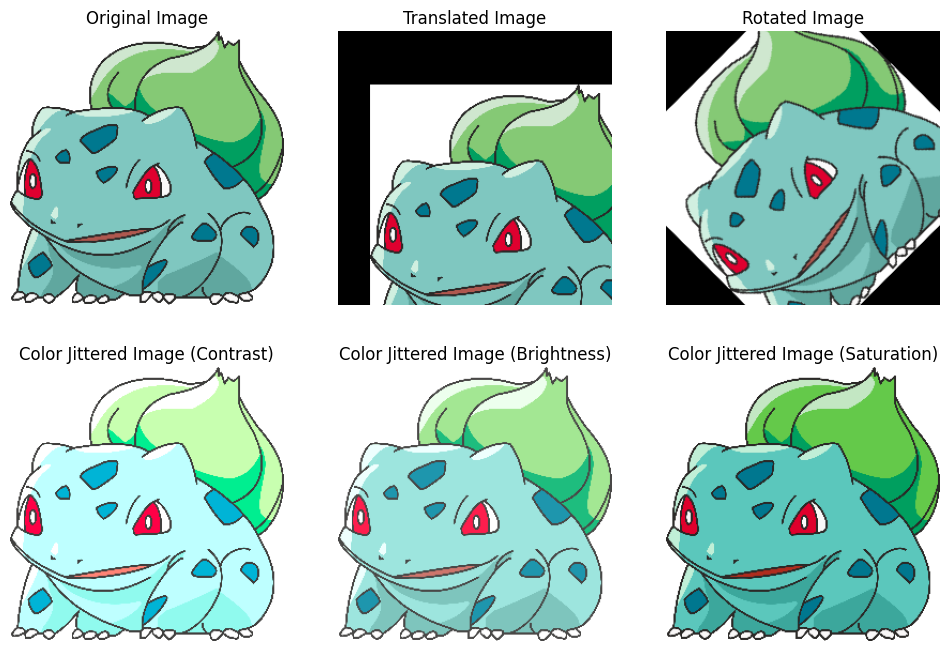

In [7]:
# Visualize the augmentations
def augment_and_display(image_path):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    translated_img = translate_image(img, tx=30, ty=50)
    rotated_img = rotate_image(img, angle=45)
    jittered_img_c = color_jitter(img, c_factor=1.5)
    jittered_img_b = color_jitter(img, b_factor=30)
    jittered_img_s = color_jitter(img, s_factor=1.5)

    plt.figure(figsize=(12, 8))
    plt.subplot(2, 3, 1)
    plt.imshow(img)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(translated_img)
    plt.title('Translated Image')
    plt.axis('off')
    plt.subplot(2, 3, 3)
    plt.imshow(rotated_img)
    plt.title('Rotated Image')
    plt.axis('off')
    plt.subplot(2, 3, 4)
    plt.imshow(jittered_img_c)
    plt.title('Color Jittered Image (Contrast)')
    plt.axis('off')
    plt.subplot(2, 3, 5)
    plt.imshow(jittered_img_b)
    plt.title('Color Jittered Image (Brightness)')
    plt.axis('off')
    plt.subplot(2, 3, 6)
    plt.imshow(jittered_img_s)
    plt.title('Color Jittered Image (Saturation)')
    plt.axis('off')
    plt.show()

if __name__ == '__main__':
    sample_image_path = os.path.join(image_dir, pokemon_images['Bulbasaur'][0])
    augment_and_display(sample_image_path)

Next, we will augment our data. Feel free to adjust the augmentation parameters and the number of augmented images as needed.

In [8]:
# Augment data until each pokemon has at least TARGET_COUNT images
if __name__ == '__main__':
    TARGET_COUNT = 200
    for pokemon, images in pokemon_images.items():
        current_count = len(images)
        idx = 0
        while current_count < TARGET_COUNT:
            img_path = os.path.join(image_dir, images[idx % len(images)])
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            # Apply random augmentation
            tx = np.random.randint(-20, 20)
            ty = np.random.randint(-20, 20)
            angle = np.random.randint(-30, 30)
            c_factor = np.random.uniform(0.8, 1.2)
            b_factor = np.random.randint(-20, 20)
            s_factor = np.random.uniform(0.8, 1.2)

            augmented_img = translate_image(img, tx, ty)
            augmented_img = rotate_image(augmented_img, angle)
            augmented_img = color_jitter(augmented_img, c_factor, b_factor, s_factor)

            new_image_name = f"{pokemon}_aug_{current_count}.png"
            new_image_path = os.path.join(image_dir, new_image_name)
            cv2.imwrite(new_image_path, cv2.cvtColor(augmented_img, cv2.COLOR_RGB2BGR))

            images.append(new_image_name)
            current_count += 1
            idx += 1

# Image Classification

In this section, we will use the augmented images to train a CNN model to predict the Pokemon class of an input image. First, we will prepare the data:
- `X` stores each image as a numpy array with the shape (IMG_SIZE, IMG_SIZE, 3).
- `y` contains the one-hot encoded labels.

Then split them into training and testing dataset.

In [9]:
# Prepare the dataset for image classification training
if __name__ == '__main__':
    # Don't change the code in this cell, especially the pokemon_label_list. The order of labels matters.
    pokemon_label_list = ['Bulbasaur', 'Charmander', 'Diglett', 'Dugtrio', 'Jigglypuff', 'Magikarp', 'Pikachu', 'Raichu', 'Squirtle', 'Starmie']
    files = [f for f in os.listdir(image_dir)]
    X = []
    y = []
    for f in files:
        pokemon_name = f.split('_', 1)[0]
        if pokemon_name in pokemon_label_list:
            img_path = os.path.join(image_dir, f)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # resize to 64x64
            img = img / 255.0  # normalize to [0, 1]
            X.append(img)
            y.append(pokemon_label_list.index(pokemon_name))
    X = np.array(X)
    y = np.array(y)
    y = y.reshape(-1, 1)
    encoder = OneHotEncoder()
    y = encoder.fit_transform(y).toarray()

    print(f"shape of X: {X.shape}")
    print(f"shape of y: {y.shape}")

shape of X: (2000, 64, 64, 3)
shape of y: (2000, 10)


In [10]:
# Split the dataset into training and testing sets
if __name__ == '__main__':
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print(f"shape of X_train: {X_train.shape}")
    print(f"shape of X_test: {X_test.shape}")
    print(f"shape of y_train: {y_train.shape}")
    print(f"shape of y_test: {y_test.shape}")

shape of X_train: (1600, 64, 64, 3)
shape of X_test: (400, 64, 64, 3)
shape of y_train: (1600, 10)
shape of y_test: (400, 10)


In [11]:
def get_cnn_model():
    # TODO (Task 4): Complete the CNN model architecture based on the instructions

    model = Sequential([
        Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(64, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(128, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(128, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.4),
        Dense(10, activation='softmax')
    ])



    model.compile(
        optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


    return model # Replace None with the model

if __name__ == '__main__':
    cnn_model = get_cnn_model()
    cnn_model.build(input_shape=(None, IMG_SIZE, IMG_SIZE, 3))
    cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 767,946 (2.93 MB)

 Trainable params: 767,946 (2.93 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
if __name__ == '__main__':
    # TODO (Task 5): Train the CNN model. Feel free to change the codes below
    history = cnn_model.fit(X_train, y_train, epochs=30, batch_size=30, validation_data=(X_test, y_test))

Epoch 1/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 26s 276ms/step - accuracy: 0.2194 - loss: 2.0580 - val_accuracy: 0.3425 - val_loss: 1.8169
Epoch 2/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4087 - loss: 1.5811 - val_accuracy: 0.5625 - val_loss: 1.2551
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6012 - loss: 1.1196 - val_accuracy: 0.7200 - val_loss: 0.8781
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7281 - loss: 0.7856 - val_accuracy: 0.7950 - val_loss: 0.6601
Epoch 5/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7975 - loss: 0.5615 - val_accuracy: 0.8250 - val_loss: 0.4810
Epoch 6/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8319 - loss: 0.4753 - val_accuracy: 0.8225 - val_loss: 0.5358
Epoch 7/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8712 - loss: 0.3574 - val_accuracy: 0.8675 - val_loss: 0.4339
Epoch 8/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9119 - loss: 0.2435 - val_accuracy: 0.8800 - val_

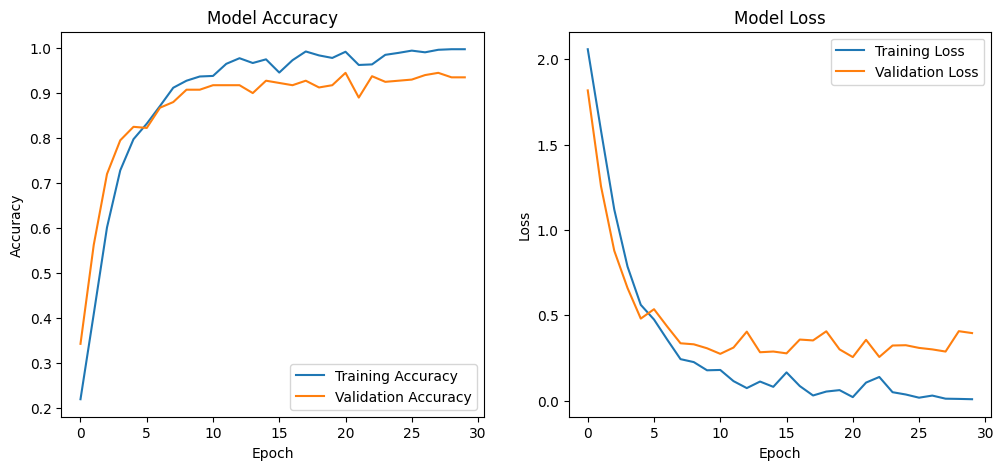

In [13]:
# Plot your CNN model's training and validation accuracy and loss curves
if __name__ == '__main__':
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

In [14]:
# Generate and display the confusion matrix
if __name__ == '__main__':
    predictions = cnn_model.predict(X_test)
    predicted_classes = np.argmax(predictions, axis=1)
    predicted_classes = [pokemon_label_list[i] for i in predicted_classes]
    true_labels = np.argmax(y_test, axis=1)
    true_labels = [pokemon_label_list[i] for i in true_labels]

    confusion_mtx = pd.crosstab(pd.Series(true_labels, name='Actual'), pd.Series(predicted_classes, name='Predicted'))
    print(confusion_mtx)

13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 213ms/step
Predicted   Bulbasaur  Charmander  Diglett  Dugtrio  Jigglypuff  Magikarp  \
Actual                                                                      
Bulbasaur          39           0        0        0           0         0   
Charmander          0          35        0        1           0         1   
Diglett             0           0       41        5           0         0   
Dugtrio             0           0        0       35           0         0   
Jigglypuff          0           0        0        0          43         0   
Magikarp            0           0        0        0           0        28   
Pikachu             0           1        0        2           0         0   
Raichu              0           2        0        1           0         0   
Squirtle            0           0        0        0           0         0   
Starmie             0           0        0        0           0         0   

Predicted   Pikachu  Raichu  Squir

Just for fun: Run the following cell to see if your model passes the CAPTCHA test.

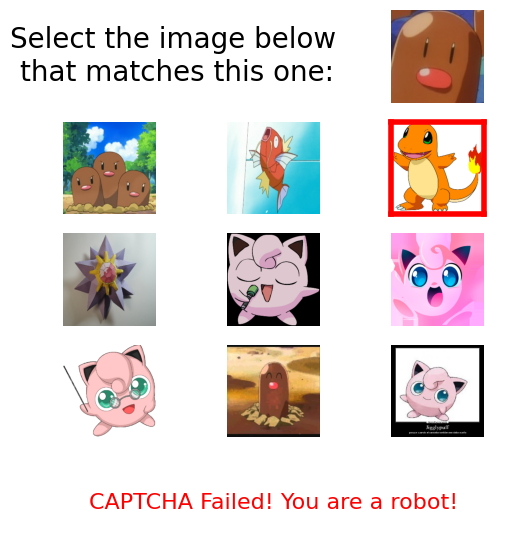

In [15]:
# A simple CAPTCHA using the trained CNN model
if __name__ == '__main__':
    import random


    random_pokemon = np.random.choice(pokemon_label_list)
    images_of_random_pokemon = [f for f in os.listdir(image_dir) if f.startswith(random_pokemon) and "aug" not in f]
    same_pokemon_images = np.random.choice(images_of_random_pokemon, size=2, replace=False)
    same_pokemon_images = [os.path.join(image_dir, f) for f in same_pokemon_images]

    images_of_other_pokemon = [f for f in os.listdir(image_dir) if not f.startswith(random_pokemon) and "aug" not in f]
    other_images = np.random.choice(images_of_other_pokemon, size=8, replace=False)
    other_images = [os.path.join(image_dir, f) for f in other_images]

    this_image = same_pokemon_images[0]
    below_images = [same_pokemon_images[1]] + other_images
    random.shuffle(below_images)
    this_image_pred = cnn_model.predict(np.array([cv2.resize(cv2.cvtColor(cv2.imread(this_image), cv2.COLOR_BGR2RGB), (IMG_SIZE, IMG_SIZE))]), verbose=0)[0]
    this_image_pred_label = np.argmax(this_image_pred)
    below_image_preds = cnn_model.predict(np.array([cv2.resize(cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB), (IMG_SIZE, IMG_SIZE)) for img_path in below_images]), verbose=0)
    best_matched_indices = np.argmax(below_image_preds[:, this_image_pred_label])

    plt.figure(figsize=(6,7))

    text = "Select the image below \nthat matches this one:"
    ax1 = plt.subplot(5, 3, 1)
    ax1.text(1.0, 0.5, text, ha='center', va='center', fontsize=20)
    ax1.axis('off')

    plt.subplot(5, 3, 2)
    plt.axis('off')

    plt.subplot(5, 3, 3)
    img = cv2.imread(this_image)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.axis('off')
    for i, img_path in enumerate(below_images):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(5, 3, i + 4)
        plt.imshow(img)
        plt.axis('off')
        if i == best_matched_indices:
            plt.axis('on')
            plt.gca().spines['top'].set_color('red')
            plt.gca().spines['top'].set_linewidth(4)
            plt.gca().spines['bottom'].set_color('red')
            plt.gca().spines['bottom'].set_linewidth(4)
            plt.gca().spines['left'].set_color('red')
            plt.gca().spines['left'].set_linewidth(4)
            plt.gca().spines['right'].set_color('red')
            plt.gca().spines['right'].set_linewidth(4)
            plt.gca().tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    plt.subplot(5, 3, 13)
    plt.axis('off')
    plt.subplot(5, 3, 15)
    plt.axis('off')

    ax14 = plt.subplot(5, 3, 14)
    ax14.axis('off')
    if best_matched_indices == below_images.index(same_pokemon_images[1]):
        ax14.text(0.5, 0.5, "CAPTCHA Passed! You are human.", ha='center', va='center', fontsize=16, color='green')
    else:
        ax14.text(0.5, 0.5, "CAPTCHA Failed! You are a robot!", ha='center', va='center', fontsize=16, color='red')
    plt.show()

In [ ]:
if __name__ == '__main__':
  cnn_model.save("cnn_model.keras")

# Image Denoising
After training the CNN, your model can predict any Pokemon images from the ten classes. Or can it? Due to environmental factors or compression artifacts, the input images may contain noise, which can negatively affect your model's performance. This is where image denoising comes in, removing unwanted noise from the images.

In [17]:
# Function to randomly add gaussian noise and salt-and-pepper noise to the image
def add_noise(normalized_image):
    normalized_image = normalized_image.copy()
    gaussian_noise = np.random.normal(0, 0.05, (IMG_SIZE, IMG_SIZE, 3))
    normalized_image = np.clip(normalized_image + gaussian_noise, 0, 1)

    salt_pepper_prob = 0.08
    rand_matrix = np.random.rand(IMG_SIZE, IMG_SIZE, 3)
    normalized_image[rand_matrix < (salt_pepper_prob / 2)] = 0
    normalized_image[rand_matrix > (1 - salt_pepper_prob / 2)] = 1

    return normalized_image

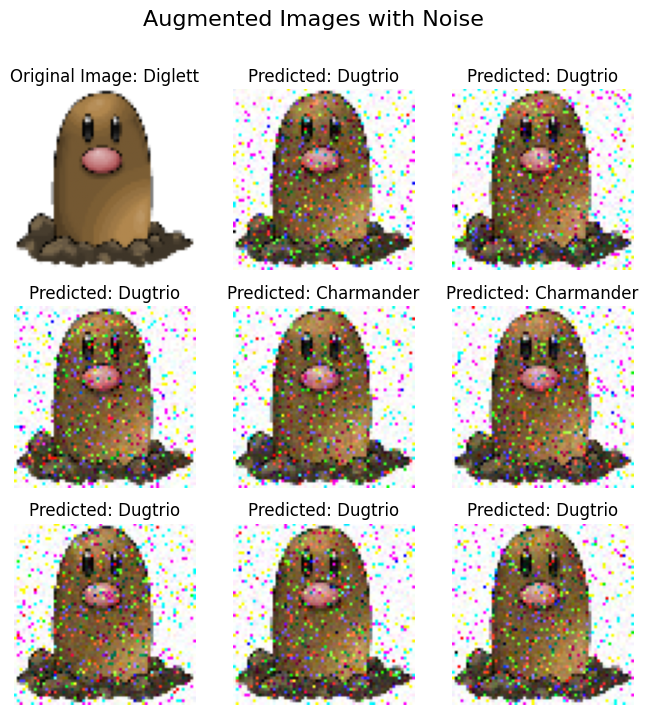

In [18]:

if __name__ == '__main__':
    plt.figure(figsize=(8, 8))
    img_path = os.path.join(image_dir, 'Diglett_0.png')
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    plt.subplot(3, 3, 1)
    plt.title('Original Image: Diglett')
    plt.imshow(img)
    plt.axis('off')
    for i in range(1, 9):
        plt.subplot(3, 3, i+1)
        noisy_img = add_noise(img)
        pred = cnn_model.predict(np.array([noisy_img]), verbose=0)
        plt.title(f'Predicted: {pokemon_label_list[np.argmax(pred)]}')
        plt.imshow(noisy_img)
        plt.axis('off')
    plt.suptitle('Augmented Images with Noise', fontsize=16)
    plt.show()

First, we will prepare the data:
- `X` stores each image as a numpy array with the shape (IMG_SIZE, IMG_SIZE, 3).
- `X_noisy` stores the noisy version of each image in `X`, having the same shape as `X`.

Next, we will prepare the training and testing datasets:
- `X_train`, `X_test`: The training and testing data for the model input — the noisy images.
- `y_train`, `y_test`: The training and testing data for the model output — the original images.

In [19]:
if __name__ == '__main__':
    files = [f for f in os.listdir(image_dir)]
    X_noisy = []
    X = []
    for f in files:
        pokemon_name = f.split('_', 1)[0]
        if pokemon_name in pokemon_label_list and "aug" not in f:
            img_path = os.path.join(image_dir, f)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # resize to 64x64
            img = img / 255.0  # normalize to [0, 1]
            for i in range(5):  # augment each image 5 times
                noisy_img = add_noise(img)
                X_noisy.append(noisy_img)
                X.append(img)
    X_noisy = np.array(X_noisy)
    X = np.array(X)
    X_train, X_test, y_train, y_test = train_test_split(X_noisy, X, test_size=0.2, random_state=42)
    print(f"shape of X_train: {X_train.shape}")
    print(f"shape of y_train: {y_train.shape}")
    print(f"shape of X_test: {X_test.shape}")
    print(f"shape of y_test: {y_test.shape}")

shape of X_train: (3760, 64, 64, 3)
shape of y_train: (3760, 64, 64, 3)
shape of X_test: (940, 64, 64, 3)
shape of y_test: (940, 64, 64, 3)


In [20]:
def get_auto_encoder():
    # TODO (Task 6): Complete the convolutional auto-encoder architecture based on the instructions
    model = Sequential([
        Conv2D(32, (3,3), activation='elu', padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        MaxPooling2D((2,2)),

        Conv2D(64, (3,3), activation='elu', padding='same'),
        MaxPooling2D((2,2)),

        Conv2D(128, (3,3), activation='elu', padding='same'),
        MaxPooling2D((2,2)),

        Conv2D(128, (3, 3), activation='elu', padding='same'),
        UpSampling2D((2, 2), interpolation='bilinear'),

        Conv2D(128, (3, 3), activation='elu', padding='same'),
        UpSampling2D((2, 2), interpolation='bilinear'),

        Conv2D(64, (3, 3), activation='elu', padding='same'),
        UpSampling2D((2, 2), interpolation='bilinear'),


        Conv2D(64, (3, 3), activation='elu', padding='same'),


        Conv2D(3, (3, 3), activation='sigmoid', padding='same'),
    ])

    model.compile(
      optimizer='adam',
      loss='mse',
      metrics=['mae']
  )


    return model  # Replace None with the model

if __name__ == '__main__':
    auto_encoder = get_auto_encoder()
    auto_encoder.build(input_shape=(None, IMG_SIZE, IMG_SIZE, 3))
    auto_encoder.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 3)      │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 500,867 (1.91 MB)

 Trainable params: 500,867 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

It is now time to train the auto-encoder you built in the previous tasks. You are free to explore different configurations of parameters. However, keep in mind that increasing the number of training epochs requires more computational resources and time, and it does not necessarily indicate better model performance due to the potential for overfitting.

**Task 7**: Train your auto-encoder.

In [21]:
if __name__ == '__main__':
  history = auto_encoder.fit(x=X_train, y=y_train, epochs=75, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 43s 217ms/step - loss: 0.0489 - mae: 0.1616 - val_loss: 0.0287 - val_mae: 0.1193
Epoch 2/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.0262 - mae: 0.1110 - val_loss: 0.0236 - val_mae: 0.1053
Epoch 3/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0223 - mae: 0.0981 - val_loss: 0.0212 - val_mae: 0.0944
Epoch 4/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.0205 - mae: 0.0916 - val_loss: 0.0206 - val_mae: 0.0956
Epoch 5/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.0193 - mae: 0.0870 - val_loss: 0.0189 - val_mae: 0.0839
Epoch 6/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0197 - mae: 0.0887 - val_loss: 0.0186 - val_mae: 0.0830
Epoch 7/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0180 - mae: 0.0824 - val_loss: 0.0179 - val_mae: 0.0820
Epoch 8/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0175 - mae: 0.0805 - val_loss: 0.0172 - val_mae: 0.0766
Epoch 9/75
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 38m

In [ ]:
# Plotting the auto-encoder's training and validation loss curves
if __name__ == '__main__':
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Auto-Encoder Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['mae'], label='Training MAE')
    plt.plot(history.history['val_mae'], label='Validation MAE')
    plt.title('Auto-Encoder MAE')
    plt.xlabel('Epoch')
    plt.ylabel('MAE')
    plt.legend()

    plt.show()

In [ ]:
# Visualizing the denoising results
# denoised images are much clearer than the noisy images

if __name__ == '__main__':
    plt.figure(figsize=(8, 8))
    noisy_img = random.sample(list(X_noisy), 3)
    for i in range(0, 3):
        plt.subplot(3, 3, i*3 + 1)
        plt.title(f"Noisy Image {i+1}")
        plt.imshow(noisy_img[i])
        plt.axis('off')
        plt.subplot(3, 3, i*3 + 2)
        plt.text(0.5, 0.5, "=>", fontsize=30, ha='center', va='center')
        plt.axis('off')
        plt.subplot(3, 3, i*3 + 3)
        denoised_img = auto_encoder.predict(np.array([noisy_img[i]]), verbose=0)[0]
        plt.title(f'Denoised Image {i+1}')
        plt.imshow(denoised_img)
        plt.axis('off')
    plt.suptitle('Denoising Autoencoder Results', fontsize=16)
    plt.show()

In [24]:
# Compute the PSNR between the original and denoised images
if __name__ == '__main__':
    def compute_psnr(original, denoised):
        mse = np.mean((original - denoised) ** 2)
        if mse == 0: # most likely it won't happen
            return 100
        psnr = 10 * np.log10(1.0 / np.sqrt(mse))
        return psnr
    psnr_denoised = []
    psnr_noisy = []
    sample_X = random.sample(list(X), 100)
    for i in range(len(sample_X)):
        noisy_img = add_noise(sample_X[i])
        denoised_img = auto_encoder.predict(np.array([noisy_img]), verbose=0)[0]
        psnr_denoised.append(compute_psnr(sample_X[i], denoised_img))
        psnr_noisy.append(compute_psnr(sample_X[i], noisy_img))
    average_noisy_psnr = np.mean(psnr_noisy)
    average_psnr = np.mean(psnr_denoised)
    print(f"Average PSNR between original and denoised images: {average_psnr:.2f} dB")
    print(f"Average PSNR between original and noisy images: {average_noisy_psnr:.2f} dB")
    print(f"PSNR Improvement (%) : {(average_psnr - average_noisy_psnr) / average_noisy_psnr * 100:.2f} %")

Average PSNR between original and denoised images: 10.58 dB
Average PSNR between original and noisy images: 7.39 dB
PSNR Improvement (%) : 43.20 %


In [30]:
if __name__ == '__main__':
  auto_encoder.save("auto_encoder.keras")

In [34]:
if __name__ == '__main__':
    # Load the dataset again to get the original images and labels for testing the CNN model on noisy images
    pokemon_label_list = ['Bulbasaur', 'Charmander', 'Diglett', 'Dugtrio', 'Jigglypuff', 'Magikarp', 'Pikachu', 'Raichu', 'Squirtle', 'Starmie']
    files = [f for f in os.listdir(image_dir)]
    X = []
    noisy_X = []
    y = []
    for f in files:
        pokemon_name = f.split('_', 1)[0]
        if pokemon_name in pokemon_label_list:
            img_path = os.path.join(image_dir, f)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # resize to 64x64
            img = img / 255.0  # normalize to [0, 1]
            X.append(img)
            noisy_X.append(add_noise(img))
            y.append(pokemon_label_list.index(pokemon_name))
    X = np.array(X)
    noisy_X = np.array(noisy_X)
    y = np.array(y)
    y = y.reshape(-1, 1)

    # Load the trained CNN model and the auto-encoder model
    from keras.models import load_model
    cnn_model = load_model('cnn_model.keras')
    autoencoder_model = load_model('auto_encoder.keras')


    # Labels as a flat integer array
    y_true = y.flatten().astype(int)

    # Accuracy on noisy images
    noisy_pred = np.argmax(cnn_model.predict(noisy_X), axis=1)
    noisy_acc = np.mean(noisy_pred == y_true)

    # Accuracy on denoised images
    denoised_X = autoencoder_model.predict(noisy_X)
    denoised_pred = np.argmax(cnn_model.predict(denoised_X), axis=1)
    denoised_acc = np.mean(denoised_pred == y_true)

    print(f"CNN accuracy on noisy images:    {noisy_acc:.4f} ({noisy_acc * 100:.2f}%)")
    print(f"CNN accuracy on denoised images: {denoised_acc:.4f} ({denoised_acc * 100:.2f}%)")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
CNN accuracy on noisy images:    0.8280 (82.80%)
CNN accuracy on denoised images: 0.9600 (96.00%)


Disclaimer: Please do not use this in the real world, I wont be responsible. It is very unethical.